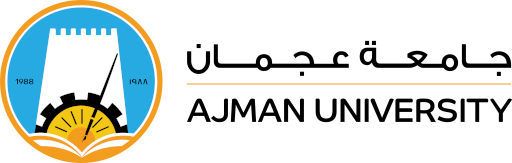

<p>
College: Engineering and Information Technology<br>
Department: Information Technology<br>
Program: Data Analytics<br>
Academic Semester: Spring 2025-2026<br>
Course: DAT405 Machine Learning Lab<br>
Course Instructor: Dr. Mahmoud AlShboul<br>
</p></center>

Student ID: ________________ <br />
Student Name: _________________

# **Lab 6: Convolutional Neural Networks - CNNs**

## Convolutional Neural Networks
Convolutional Neural Networks (CNNs), also known as ConvNets, are a class of deep learning models primarily designed for processing and analyzing visual data, such as images and videos. They have revolutionized various computer vision tasks, including image classification, object detection, facial recognition, and more. CNNs are inspired by the organization of the human visual system and are highly effective at automatically learning and extracting hierarchical features from raw pixel data.

## CNN Layers

**Convolutional Layers**: CNNs are built around convolutional layers, which are responsible for feature extraction. In these layers, small filters (also called kernels) slide or convolve over the input image to detect patterns and features. Convolution operations allow CNNs to capture local patterns like edges, textures, and simple shapes.

<img src="Convolution Operation.gif" />

**Pooling Layers**: After convolution, pooling layers are often used to reduce the spatial dimensions of the feature maps while retaining essential information. Max-pooling and average-pooling are common pooling techniques used in CNNs. Pooling helps in reducing computation and making the model more robust to variations in object position and scale.

<img src="MaxPooling.gif" />

**Activation Functions**: Activation functions like ReLU (Rectified Linear Unit) are applied to the output of convolutional and pooling layers to introduce non-linearity into the model. This non-linearity is crucial for CNNs to learn complex features and patterns.

**Fully Connected Layers**: After several convolutional and pooling layers, CNNs often have one or more fully connected layers. These layers are similar to the traditional artificial neural networks and are responsible for making predictions based on the learned features. They are typically found at the end of the network.

**Softmax Layer**: For classification tasks, CNNs usually end with a softmax layer. This layer assigns probabilities to each possible class, allowing the network to make predictions. The class with the highest probability is chosen as the final prediction.

**Backpropagation and Training**: CNNs are trained using backpropagation, which involves updating the network's weights and biases to minimize a predefined loss function. Common optimization algorithms like stochastic gradient descent (SGD) and its variants are used for this purpose.


## Classification with Convolutional Neural Networks (on MNIST)

Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9570 - loss: 0.1386 - val_accuracy: 0.9858 - val_loss: 0.0469
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9858 - loss: 0.0459 - val_accuracy: 0.9870 - val_loss: 0.0400
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9898 - loss: 0.0326 - val_accuracy: 0.9885 - val_loss: 0.0406
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9918 - loss: 0.0254 - val_accuracy: 0.9884 - val_loss: 0.0354
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9938 - loss: 0.0194 - val_accuracy: 0.9896 - val_loss: 0.0340
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9944 - loss: 0.0169 - val_accuracy: 0.9919 - val_loss: 0.0282
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9954 - loss: 0.0134 - val_accuracy: 0.9905 - val_loss: 0.0353
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9961 - loss: 0

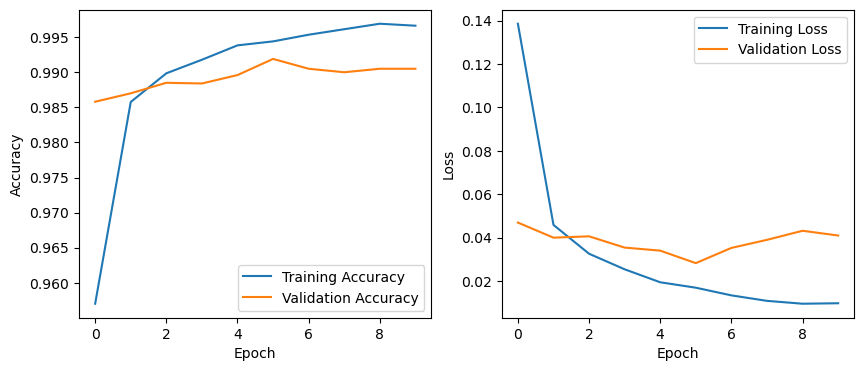

In [ ]:
# Import the necessary libraries
import tensorflow as tf                      # TensorFlow library for deep learning
from keras import datasets, layers, models   # Import common Keras components
import matplotlib.pyplot as plt              # For plotting graphs (accuracy/loss)

# -------------------------------------------------------------------------
# Load and preprocess the MNIST dataset
# -------------------------------------------------------------------------

# The MNIST dataset contains 70,000 grayscale images of handwritten digits (0–9)
# Split into 60,000 training images and 10,000 test images
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()

# Normalize the pixel values to the range [0, 1]
# This helps the neural network train faster and more efficiently
train_images, test_images = train_images / 255.0, test_images / 255.0

# -------------------------------------------------------------------------
# Build the Convolutional Neural Network (CNN)
# -------------------------------------------------------------------------

# Use the Sequential API to stack layers one after another
model = models.Sequential([
    # First convolutional layer: detects simple features like edges
    # 32 filters, each of size 3x3, with ReLU activation
    # Input shape: 28x28 grayscale image (1 channel)
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    
    # MaxPooling layer: reduces spatial dimensions (downsampling)
    # Takes the maximum value from each 2x2 block
    layers.MaxPooling2D((2, 2)),

    # Second convolutional layer: detects more complex features
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Second pooling layer: again reduces image size
    layers.MaxPooling2D((2, 2)),

    # Third convolutional layer: detects even more abstract features
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Flatten layer: converts 2D feature maps into a 1D vector
    # Needed before passing data to fully connected (Dense) layers
    layers.Flatten(),

    # Fully connected layer with 64 neurons and ReLU activation
    # Learns non-linear combinations of the extracted features
    layers.Dense(64, activation='relu'),

    # Output layer: 10 neurons (one per digit class: 0–9)
    # No activation here because we'll apply a softmax later
    layers.Dense(10)
])

# -------------------------------------------------------------------------
# Compile the CNN model
# -------------------------------------------------------------------------

# Configure the model for training
model.compile(
    optimizer='adam',  # Adaptive Moment Estimation optimizer (efficient and widely used)
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    # SparseCategoricalCrossentropy is used because labels are integers (not one-hot encoded)
    metrics=['accuracy']  # Track accuracy during training and evaluation
)

# -------------------------------------------------------------------------
# Train the model
# -------------------------------------------------------------------------

# Add a new axis to images to match the expected input shape (28, 28, 1)
# Fit the model for 10 epochs using the training data
# Validate performance on the test dataset after each epoch
history = model.fit(
    train_images[..., tf.newaxis],  # Add a channel dimension
    # This extra dimension is required because convolutional layers expect 3D input per image:
    # (height, width, channels)
    train_labels,                   # True labels for training
    epochs=10,                      # Number of training iterations
    validation_data=(test_images[..., tf.newaxis], test_labels)  # Validation data
)

# -------------------------------------------------------------------------
# Evaluate the trained model
# -------------------------------------------------------------------------

# Evaluate the model on the unseen test dataset
# verbose=2 shows a summary line per evaluation
test_loss, test_acc = model.evaluate(test_images[..., tf.newaxis], test_labels, verbose=2)

# Print the test accuracy result
print(f"Test accuracy: {test_acc}")

# -------------------------------------------------------------------------
# Visualize training results
# -------------------------------------------------------------------------

# Create a figure with two subplots side by side
plt.figure(figsize=(10, 4))

# Plot training and validation accuracy per epoch
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot training and validation loss per epoch
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Display the plots
plt.show()

# Question: When do we stop training the model?
# Answer: Stop training when validation loss stops decreasing — even if training loss keeps going down.

## Identifying overfitting, underfitting and good fit.

**Good Fit:**

- Training and validation losses decrease together and plateau close to each other.

- Model generalizes well.

**Overfitting:**

- Training loss keeps decreasing.

- Validation loss decreases at first but then starts increasing → model memorizes training data.

**Underfitting:**

- Both training and validation losses remain high and flat.

- Model is too simple or not trained enough.

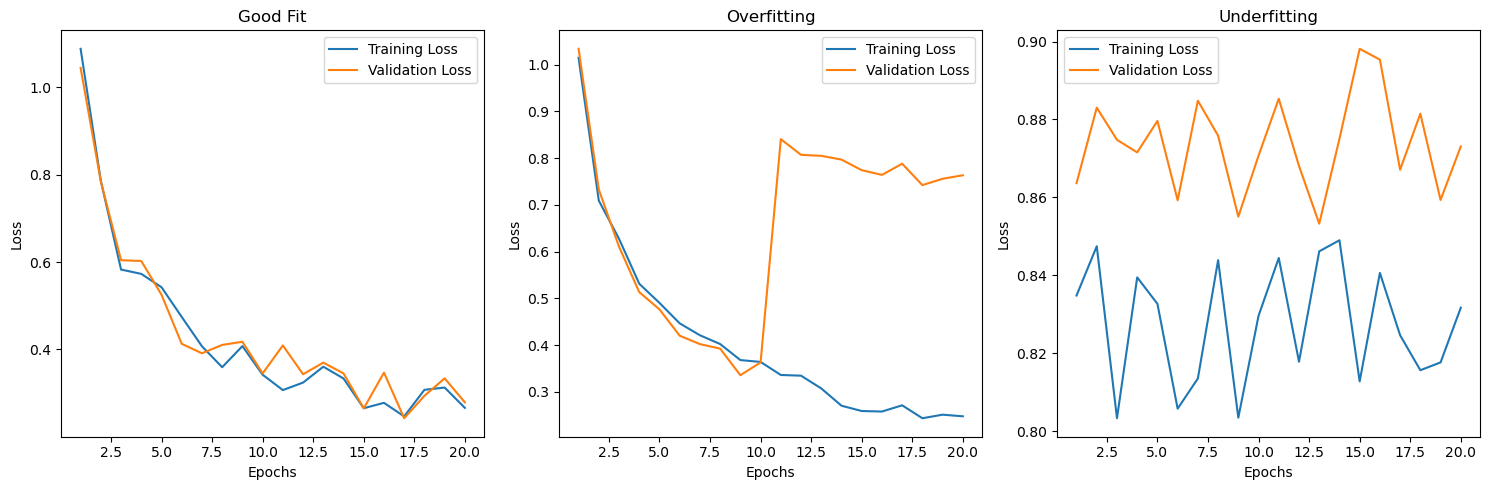

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

epochs = np.arange(1, 21)

# Simulated loss curves

# Good Fit
train_loss_good = 1 / (epochs**0.5) + 0.1*np.random.rand(20)
val_loss_good   = 1 / (epochs**0.5) + 0.12*np.random.rand(20)

# Overfitting
train_loss_over = 1 / (epochs**0.5) + 0.05*np.random.rand(20)
val_loss_over   = np.concatenate([1/(epochs[:10]**0.5), 1/(epochs[10:]**0.5)+0.5]) + 0.05*np.random.rand(20)

# Underfitting
train_loss_under = 0.8 + 0.05*np.random.rand(20)
val_loss_under   = 0.85 + 0.05*np.random.rand(20)

# Plotting
plt.figure(figsize=(15, 5))

# Good Fit
plt.subplot(1, 3, 1)
plt.plot(epochs, train_loss_good, label='Training Loss')
plt.plot(epochs, val_loss_good, label='Validation Loss')
plt.title('Good Fit')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Overfitting
plt.subplot(1, 3, 2)
plt.plot(epochs, train_loss_over, label='Training Loss')
plt.plot(epochs, val_loss_over, label='Validation Loss')
plt.title('Overfitting')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Underfitting
plt.subplot(1, 3, 3)
plt.plot(epochs, train_loss_under, label='Training Loss')
plt.plot(epochs, val_loss_under, label='Validation Loss')
plt.title('Underfitting')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


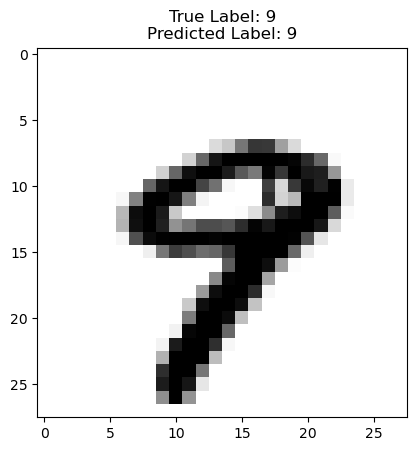

In [3]:
# Import NumPy for numerical operations
import numpy as np

# -------------------------------------------------------------------------
# Select and prepare a single test image for prediction
# -------------------------------------------------------------------------

# Choose a specific sample from the test dataset (index 9)
# You can change this number to visualize a different test image
sample_index = 9

# Extract the image (28x28 array) and its true label
sample_image = test_images[sample_index]
sample_label = test_labels[sample_index]

# -------------------------------------------------------------------------
# Preprocess the image for model prediction
# -------------------------------------------------------------------------

# The model expects input in 4D shape: (batch_size, height, width, channels)
# Here, we add two new dimensions:
# - np.newaxis at the start: adds a batch dimension (batch size = 1)
# - np.newaxis at the end: adds a channel dimension (1 channel for grayscale)
model_input = sample_image[np.newaxis, ..., np.newaxis]

# -------------------------------------------------------------------------
# Make a prediction using the trained CNN model
# -------------------------------------------------------------------------

# Get the raw prediction scores (logits) from the model
# The output is a 1x10 array representing probabilities for digits 0–9
predictions = model.predict(model_input)

# Get the index (0–9) of the class with the highest predicted probability
predicted_label = np.argmax(predictions)

# -------------------------------------------------------------------------
# Display the test image and prediction results
# -------------------------------------------------------------------------

# Create a new figure for visualization
plt.figure()

# Display the selected test image in grayscale
plt.imshow(sample_image, cmap=plt.cm.binary)

# Add a title showing the true and predicted labels
plt.title(f"True Label: {sample_label}\nPredicted Label: {predicted_label}")

# Show the figure
plt.show()


## CIFAR10 CNN Example

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 21s 0us/step
Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.4247 - loss: 1.5718 - val_accuracy: 0.5367 - val_loss: 1.2752
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 12s 8ms/step - accuracy: 0.5739 - loss: 1.1982 - val_accuracy: 0.6105 - val_loss: 1.1049
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6283 - loss: 1.0562 - val_accuracy: 0.6499 - val_loss: 1.0025
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.6602 - loss: 0.9613 - val_accuracy: 0.6493 - val_loss: 1.0065
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.6897 - loss: 0.8910 - val_accuracy: 0.6815 - val_loss: 0.9136
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.7063 - loss: 0.8352 - val_accuracy: 0.6864 - val_loss: 0.9045
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.7237 - loss: 0.7899 - val_accuracy: 0.6927 - val_loss: 0.8804
Epoch 8/10
1563/1563 ━━━

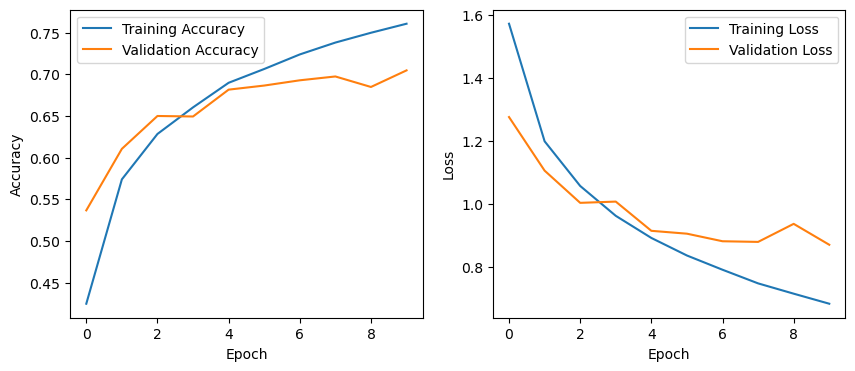

In [4]:
# -------------------------------------------------------------
# Import necessary libraries
# -------------------------------------------------------------
import tensorflow as tf                 # Deep learning framework
from keras import datasets, layers, models  # Keras tools for datasets, layers, and model building
import matplotlib.pyplot as plt          # For plotting training results

# -------------------------------------------------------------
# Load and preprocess the CIFAR-10 dataset
# -------------------------------------------------------------
# CIFAR-10 contains 60,000 color images (32x32 pixels, 3 color channels)
# with 10 classes (airplane, car, bird, cat, etc.)
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to the range [0, 1] to improve training performance
train_images, test_images = train_images / 255.0, test_images / 255.0

# -------------------------------------------------------------
# Build the Convolutional Neural Network (CNN)
# -------------------------------------------------------------
# A Sequential model allows layers to be stacked linearly
model = models.Sequential([
    # First convolutional layer
    # - 32 filters of size (3x3)
    # - Activation: ReLU (introduces non-linearity)
    # - Input shape: 32x32 image with 3 color channels (RGB)
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),

    # First pooling layer
    # - Reduces spatial dimensions by taking the maximum value in each 2x2 region
    layers.MaxPooling2D((2, 2)),

    # Second convolutional layer
    # - 64 filters of size (3x3)
    # - Learns more complex image features
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Second pooling layer
    layers.MaxPooling2D((2, 2)),

    # Third convolutional layer
    # - 64 filters again to capture higher-level features
    layers.Conv2D(64, (3, 3), activation='relu'),

    # Flatten layer
    # - Converts the 3D feature maps into a 1D vector for the dense layers
    layers.Flatten(),

    # Fully connected (dense) layer
    # - 64 neurons with ReLU activation to combine extracted features
    layers.Dense(64, activation='relu'),

    # Output layer
    # - 10 neurons (one for each CIFAR-10 class)
    # - No activation function because we’ll use logits with Softmax inside the loss
    layers.Dense(10)
])

# -------------------------------------------------------------
# Compile the CNN model
# -------------------------------------------------------------
model.compile(
    optimizer='adam',  # Adaptive learning rate optimization algorithm
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),  
    # 'from_logits=True' means the output layer gives raw scores, not probabilities
    metrics=['accuracy']  # Evaluate the model based on accuracy
)

# -------------------------------------------------------------
# Train the CNN model
# -------------------------------------------------------------
# - Feed training data for 10 epochs
# - Validate performance on test data after each epoch
history = model.fit(
    train_images, train_labels,
    epochs=10,
    validation_data=(test_images, test_labels)
)

# -------------------------------------------------------------
# Evaluate the trained model on unseen test data
# -------------------------------------------------------------
# This gives us the final test loss and accuracy
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"Test accuracy: {test_acc}")

# -------------------------------------------------------------
# Visualize training and validation performance
# -------------------------------------------------------------
plt.figure(figsize=(10, 4))

# Plot accuracy trends
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Plot loss trends
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

# Display the plots
plt.show()


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step


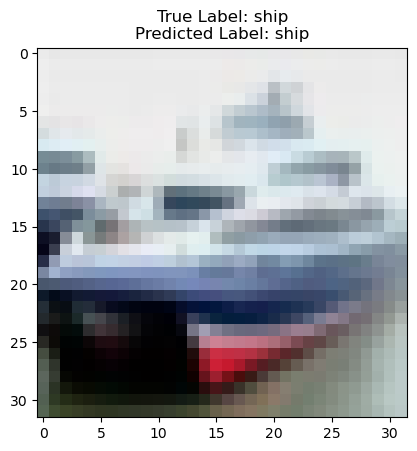

In [5]:
# -------------------------------------------------------------
# Import required libraries
# -------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# Select and prepare a test image for prediction
# -------------------------------------------------------------

# Choose which test image to inspect (you can change the index)
sample_index = 1

# Extract the image and its true label from the CIFAR-10 test dataset
sample_image = test_images[sample_index]    # Shape: (32, 32, 3)
sample_label = test_labels[sample_index]    # Example: [3]  (since CIFAR-10 labels are stored as 2D arrays)

# -------------------------------------------------------------
# Prepare the image for prediction
# -------------------------------------------------------------

# Keras models expect a batch dimension in the input: (batch_size, height, width, channels)
# np.newaxis adds this extra batch dimension at the start
# New shape becomes: (1, 32, 32, 3)
model_input = sample_image[np.newaxis, ...]

# -------------------------------------------------------------
# Use the trained CNN model to make a prediction
# -------------------------------------------------------------

# The model outputs an array of 10 values (raw class scores for each CIFAR-10 category)
predictions = model.predict(model_input)

# Get the index (0–9) of the highest predicted class probability
predicted_label = np.argmax(predictions)

# -------------------------------------------------------------
# Map numeric labels to human-readable class names
# -------------------------------------------------------------
class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

# -------------------------------------------------------------
# Display the image and prediction results
# -------------------------------------------------------------

plt.figure()  # Create a new figure window
plt.imshow(sample_image)  # Display the selected test image (in color)

# Add the true and predicted class names as the plot title
# sample_label[0] is used because CIFAR-10 labels are stored as nested arrays (e.g., [[3]])
plt.title(f"True Label: {class_names[sample_label[0]]}\nPredicted Label: {class_names[predicted_label]}")

# Show the figure on screen
plt.show()

### Let's try to improve the CIFAR10 CNN architecture
We will enhance the model by implementing a few changes:
- Let's add dropout layers and batch normalization to increase model complexity and reduce overfitting.  


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.4856 - loss: 1.4604 - val_accuracy: 0.5564 - val_loss: 1.2446
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 31s 20ms/step - accuracy: 0.6161 - loss: 1.0911 - val_accuracy: 0.5891 - val_loss: 1.2191
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 29s 19ms/step - accuracy: 0.6678 - loss: 0.9398 - val_accuracy: 0.5343 - val_loss: 1.5782
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 30s 19ms/step - accuracy: 0.7013 - loss: 0.8515 - val_accuracy: 0.6747 - val_loss: 0.9449
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 30s 19ms/step - accuracy: 0.7220 - loss: 0.7882 - val_accuracy: 0.6761 - val_loss: 0.9564
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 30s 19ms/step - accuracy: 0.7382 - loss: 0.7411 - val_accuracy: 0.6594 - val_loss: 0.9918
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 30s 19ms/step - accuracy: 0.7509 - loss: 0.7004 - val_accuracy: 0.7095 - val_loss: 0.8626
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 30s 19ms/step - accuracy: 0.7632 -

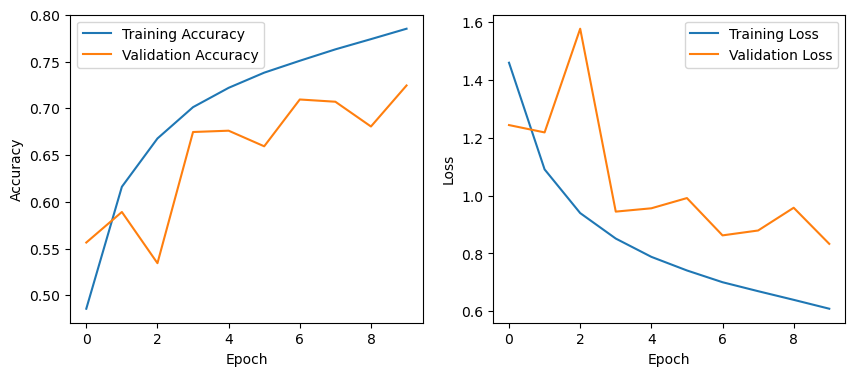

In [8]:
# -------------------------------------------------------------
# Import necessary libraries
# -------------------------------------------------------------
import tensorflow as tf
from keras import datasets, layers, models
import matplotlib.pyplot as plt

# -------------------------------------------------------------
# Load and preprocess CIFAR-10 dataset
# -------------------------------------------------------------
# CIFAR-10 contains 60,000 color images (32x32 pixels, RGB) in 10 classes
# Each class includes 6,000 images
(train_images, train_labels), (test_images, test_labels) = datasets.cifar10.load_data()

# Normalize pixel values to [0, 1] range for faster and more stable training
train_images, test_images = train_images / 255.0, test_images / 255.0

# -------------------------------------------------------------
# Build the Convolutional Neural Network (CNN)
# -------------------------------------------------------------
model = models.Sequential([

    # First convolutional block
    # - 32 filters of size 3x3 for detecting simple patterns (edges, colors)
    # - ReLU adds non-linearity
    # - BatchNormalization normalizes activations to stabilize learning
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),

    # Pooling reduces spatial size → smaller feature maps (improves efficiency)
    layers.MaxPooling2D((2, 2)),

    # Dropout randomly disables 25% of neurons during training → reduces overfitting
    layers.Dropout(0.25),

    # Second convolutional block
    # - 64 filters capture more complex features (textures, shapes)
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(0.25),

    # Third convolutional block
    # - 64 more filters for high-level features (object parts, patterns)
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.BatchNormalization(),

    # Flatten the 3D feature maps into 1D vectors for dense layers
    layers.Flatten(),

    # Fully connected layer
    # - 64 neurons combine extracted features for classification
    layers.Dense(64, activation='relu'),

    # Output layer
    # - 10 neurons for the 10 CIFAR-10 classes (0–9)
    # - No activation (logits used with Softmax inside loss function)
    layers.Dense(10)
])

# -------------------------------------------------------------
# Compile the model
# -------------------------------------------------------------
model.compile(
    optimizer='adam',  # Adaptive optimizer for efficient training
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    # 'from_logits=True' since the output layer has no softmax
    metrics=['accuracy']  # Evaluate model using accuracy metric
)

# -------------------------------------------------------------
# Train the CNN
# -------------------------------------------------------------
# Train for 10 epochs using 50,000 training images
# Validate performance using 10,000 test images each epoch
history = model.fit(
    train_images, train_labels,
    epochs=10,
    validation_data=(test_images, test_labels)
)

# -------------------------------------------------------------
# Evaluate the trained model on test data
# -------------------------------------------------------------
# Returns the final loss and accuracy on unseen test images
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"Test accuracy: {test_acc}")

# -------------------------------------------------------------
# Visualize training progress
# -------------------------------------------------------------
plt.figure(figsize=(10, 4))

# Left plot: Accuracy over epochs
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

# Right plot: Loss over epochs
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.show()


# **QUESTION**
1. **Build a simple CNN**: Implement a simple CNN model in Keras, the model should include at least one convolutional layer and one fully connected layer, use the fashion MNIST dataset for this exercise.
- **Hint**: You can start with a Conv2D layer for feature extraction, followed by Flatten and Dense layers for classification.
2. **Adding Convolutional Layers**: Extend the previous model by adding more convolutional layers and max-pooling layers, compare the results with the previous model.
- **Hint**: Use Conv2D and MaxPooling2D layers to add more model complexity for feature extraction.


The dataset is loaded below:

In [ ]:
# -------------------------------------------------------------
# Import essential libraries
# -------------------------------------------------------------
import tensorflow as tf                     # TensorFlow for building and training neural networks
from keras import datasets, layers, models  # Keras for datasets, layers, and model creation
import matplotlib.pyplot as plt             # Matplotlib for data visualization

# -------------------------------------------------------------
# Load the Fashion MNIST dataset
# -------------------------------------------------------------
# The dataset contains 70,000 grayscale images (28x28 pixels each)
# - 60,000 images for training
# - 10,000 images for testing
# Each image represents an item of clothing (e.g., T-shirt, shoe, coat)
(train_images, train_labels), (test_images, test_labels) = datasets.fashion_mnist.load_data()

# -------------------------------------------------------------
# Normalize the pixel values
# -------------------------------------------------------------
# Each pixel in the images has a value between 0 and 255.
# Dividing by 255.0 scales them to [0, 1].
# This helps the neural network train faster and perform better.
train_images, test_images = train_images / 255.0, test_images / 255.0


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 5us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 4us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Build the CNN model
